# Numerical Models of Subsurface

This notebook will be used to build numerical models of the subsurface \
These models are designed to replicate different traps seen in the seismic data\
For each kind of structure, two models will be made:
- (a) models will contain the geologic formations and properties as seen in the data
- (b) models will also contain an added hypothetical CO2 plume

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

In [2]:
#here we are making a 3D grid
x, y, z = (
    np.linspace(-7500, 7500.0, 751),
    np.linspace(-7500, 7500.0, 751),
    np.linspace(-3000.0, 0.0, 301),
)

xx, yy, zz = np.meshgrid(x, y, z, indexing="xy")

# Model 1a

Model of a pinching out porous unit

In [ ]:
#here we are defining our initial seismic velocities and density within the grid
vp1a = 2310.0 * np.ones_like(xx)
#vs1a = 1280.0 * np.ones_like(xx)
rho1a = 2320.0 * np.ones_like(xx)

#here we are defining an area where the properties will be changed
#the petrel member
ix_to_change,iy_to_change,iz_to_change=np.where((zz<0.02*xx-1300) & (zz>0.02*xx-1390) & (zz<0.01*xx-1320))
vp1a[ix_to_change,iy_to_change,iz_to_change]=3850.
#vs1a[ix_to_change,iy_to_change,iz_to_change]=2140.
rho1a[ix_to_change,iy_to_change,iz_to_change]=2430.

#below the reservoir
ix_to_change,iy_to_change,iz_to_change=np.where(zz<0.02*xx-1400)
vp1a[ix_to_change,iy_to_change,iz_to_change]=4905.
#vs1a[ix_to_change,iy_to_change,iz_to_change]=2725.
rho1a[ix_to_change,iy_to_change,iz_to_change]=2530.

#then we set the area between the cenomanian and bottom of the Eider
ix_to_change,iy_to_change,iz_to_change=np.where((zz>((0.03*xx)-1450)) & (zz<((0.02*xx)-1400)))
vp1a[ix_to_change,iy_to_change,iz_to_change]=3380.
#vs1a[ix_to_change,iy_to_change,iz_to_change]=1880.
rho1a[ix_to_change,iy_to_change,iz_to_change]=2360.


In [ ]:
#calculating acoustic impedance
AI1a=np.multiply(vp1a,rho1a)

#calculate reflectivity coefficient
RC1a = np.zeros_like(AI1a)
for x in range(751):
    for y in range(751):
        for z in range(300):
            RC1a[x,y,z] = (AI1a[x,y,z+1] - AI1a[x,y,z])/(AI1a[x,y,z+1] + AI1a[x,y,z])

In [ ]:
#here we are plotting the grid at some y value
plt.figure(figsize = (14,5))
plt.imshow(AI1a[150,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto')
#plt.plot(seis1a[375,375,:]*3000,zs, color='w')
cbar = plt.colorbar()
cbar.set_label('Acoustic Impedance',fontsize=12)
plt.title('Pinchout Model at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(-3000,0)
plt.xlim(-7500,7500)
cbar.ax.tick_params(labelsize=12)
#plt.savefig('pinchmodel.pdf')

## Model 1b

Here we will model a pinch-out of a porous unit including CO2. \
Based on east side of line 3236

In [ ]:
#here we are defining our initial seismic velocities and density within the grid
vp1b = 2310.0 * np.ones_like(xx)
#vs1b = 1280.0 * np.ones_like(xx)
rho1b = 2320.0 * np.ones_like(xx)

#here we are defining an area where the properties will be changed
#the petrel member
ix_to_change,iy_to_change,iz_to_change=np.where((zz<0.02*xx-1300) & (zz>0.02*xx-1390) & (zz<0.01*xx-1320))
vp1b[ix_to_change,iy_to_change,iz_to_change]=3850.
#vs1b[ix_to_change,iy_to_change,iz_to_change]=2140.
rho1b[ix_to_change,iy_to_change,iz_to_change]=2430.

#below the reservoir
ix_to_change,iy_to_change,iz_to_change=np.where(zz<0.02*xx-1400)
vp1b[ix_to_change,iy_to_change,iz_to_change]=4905.
#vs1b[ix_to_change,iy_to_change,iz_to_change]=2725.
rho1b[ix_to_change,iy_to_change,iz_to_change]=2530.

#then we set the area between the cenomanian and bottom of the Eider
ix_to_change,iy_to_change,iz_to_change=np.where((zz>((0.03*xx)-1450)) & (zz<((0.02*xx)-1400)))
vp1b[ix_to_change,iy_to_change,iz_to_change]=3380.
#vs1b[ix_to_change,iy_to_change,iz_to_change]=1880.
rho1b[ix_to_change,iy_to_change,iz_to_change]=2360.

#co2 plume
ix_to_change,iy_to_change,iz_to_change=np.where((zz>((0.03*xx)-1450)) & (zz<((0.02*xx)-1400)) & (zz>-1500))
vp1b[ix_to_change,iy_to_change,iz_to_change]=3040.
#vs1b[ix_to_change,iy_to_change,iz_to_change]=1790.
rho1b[ix_to_change,iy_to_change,iz_to_change]=2360.

In [ ]:
#calculating acoustic impedance
AI1b=np.multiply(vp1b,rho1b)

#calculate reflectivity coefficient
RC1b = np.zeros_like(AI1b)
for x in range(751):
    for y in range(751):
        for z in range(300):
            RC1b[x,y,z] = (AI1b[x,y,z+1] - AI1b[x,y,z])/(AI1b[x,y,z+1] + AI1b[x,y,z])

In [ ]:
#here we are plotting the grid at some y value
plt.figure(figsize = (15,6))
plt.imshow(AI1b[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto')
cbar = plt.colorbar()
cbar.set_label('Acoustic Impedance',fontsize=18)
plt.title('Pinchout Model with CO2 at y = 0 m', fontsize=20)
plt.xlabel('x (m)',fontsize=18)
plt.ylabel('Depth (m)',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.ylim(-3000,0)
plt.xlim(-7500,7500)
cbar.ax.tick_params(labelsize=18)
plt.savefig('pinchmodelco2.pdf')

# Model 2a

This model represents a reservoir forming an anticline.

In [3]:
#here we are defining our seismic velocities and density within the grid
vp2a = 2310.0 * np.ones_like(xx)
#vs2a = 1280.0 * np.ones_like(xx)
rho2a = 2320.0 * np.ones_like(xx)

#here we define the petrel properties
ix_to_change,iy_to_change,iz_to_change=np.where(((zz<(-0.000045*xx**2)+(-0.000045*yy**2)-1350)) & (zz>(-0.000045*xx**2)+(-0.000045*yy**2)-1400) & (xx**2+yy**2 < 3800**2))
vp2a[ix_to_change,iy_to_change,iz_to_change]=3850.
#vs2a[ix_to_change,iy_to_change,iz_to_change]=2140.
rho2a[ix_to_change,iy_to_change,iz_to_change]=2430.

ix_to_change,iy_to_change,iz_to_change=np.where((zz<-2000) & (zz>=-2050) & (xx**2+yy**2 >= 3800**2))
vp2a[ix_to_change,iy_to_change,iz_to_change]=3850.
#vs2a[ix_to_change,iy_to_change,iz_to_change]=2140.
rho2a[ix_to_change,iy_to_change,iz_to_change]=2430.

#here we define the eider properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<(-0.000045*xx**2)+(-0.000045*yy**2)-1440) & (zz>(-0.000045*xx**2)+(-0.000045*yy**2)-1540) & (xx**2+yy**2 < 3800**2))
vp2a[ix_to_change,iy_to_change,iz_to_change]=3380.
#vs2a[ix_to_change,iy_to_change,iz_to_change]=1880.
rho2a[ix_to_change,iy_to_change,iz_to_change]=2360.

ix_to_change,iy_to_change,iz_to_change=np.where((zz<-2100) & (zz>=-2200) & (xx**2+yy**2 >= 3800**2))
vp2a[ix_to_change,iy_to_change,iz_to_change]=3380.
#vs2a[ix_to_change,iy_to_change,iz_to_change]=1880.
rho2a[ix_to_change,iy_to_change,iz_to_change]=2360.

#defining the lower properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<(-0.000045*xx**2)+(-0.000045*yy**2)-1540) & (xx**2+yy**2 < 3800**2))
vp2a[ix_to_change,iy_to_change,iz_to_change]=4905.
#vs2a[ix_to_change,iy_to_change,iz_to_change]=2725.
rho2a[ix_to_change,iy_to_change,iz_to_change]=2530.

ix_to_change,iy_to_change,iz_to_change=np.where((zz<=-2200) & (xx**2+yy**2 >= 3800**2))
vp2a[ix_to_change,iy_to_change,iz_to_change]=4905.
#vs2a[ix_to_change,iy_to_change,iz_to_change]=2725.
rho2a[ix_to_change,iy_to_change,iz_to_change]=2530.

In [4]:
#calculating acoustic impedance
AI2a=np.multiply(vp2a,rho2a)

#calculate reflectivity coefficient
RC2a = np.zeros_like(AI2a)
for x in range(751):
    for y in range(751):
        for z in range(300):
            RC2a[x,y,z] = (AI2a[x,y,z+1] - AI2a[x,y,z])/(AI2a[x,y,z+1] + AI2a[x,y,z])

In [ ]:
#here we are plotting the grid at some y value
plt.figure(figsize = (14,5))
plt.imshow(AI2a[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect = 'auto')
cbar = plt.colorbar()
cbar.set_label('Acoustic Impedance',fontsize=16)
plt.title('Anticline Model at y = 0 m', fontsize=18)
plt.xlabel('x (m)',fontsize=16)
plt.ylabel('Depth (m)',fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
cbar.ax.tick_params(labelsize=16)
#plt.axhline(y=-1350)
#plt.plot(seis2a[375,375,:]*3000,z, color='w')
plt.savefig('anticlinemodel.pdf')

## Model 2b

An anticline reservoir containing CO2

In [5]:
#here we are defining our seismic velocities and density within the grid
vp2b = 2310.0 * np.ones_like(xx)
#vs2b = 1280.0 * np.ones_like(xx)
rho2b = 2320.0 * np.ones_like(xx)

#here we define the petrel properties
ix_to_change,iy_to_change,iz_to_change=np.where(((zz<(-0.000045*xx**2)+(-0.000045*yy**2)-1350)) & (zz>(-0.000045*xx**2)+(-0.000045*yy**2)-1400) & (xx**2+yy**2 < 3800**2))
vp2b[ix_to_change,iy_to_change,iz_to_change]=3850.
#vs2b[ix_to_change,iy_to_change,iz_to_change]=2140.
rho2b[ix_to_change,iy_to_change,iz_to_change]=2430.

ix_to_change,iy_to_change,iz_to_change=np.where((zz<-2000) & (zz>=-2050) & (xx**2+yy**2 >= 3800**2))
vp2b[ix_to_change,iy_to_change,iz_to_change]=3850.
#vs2b[ix_to_change,iy_to_change,iz_to_change]=2140.
rho2b[ix_to_change,iy_to_change,iz_to_change]=2430.

#here we define the eider properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<(-0.000045*xx**2)+(-0.000045*yy**2)-1440) & (zz>(-0.000045*xx**2)+(-0.000045*yy**2)-1540) & (xx**2+yy**2 < 3800**2))
vp2b[ix_to_change,iy_to_change,iz_to_change]=3380.
#vs2b[ix_to_change,iy_to_change,iz_to_change]=1880.
rho2b[ix_to_change,iy_to_change,iz_to_change]=2360.

ix_to_change,iy_to_change,iz_to_change=np.where((zz<-2100) & (zz>=-2200) & (xx**2+yy**2 >= 3800**2))
vp2b[ix_to_change,iy_to_change,iz_to_change]=3380.
#vs2b[ix_to_change,iy_to_change,iz_to_change]=1880.
rho2b[ix_to_change,iy_to_change,iz_to_change]=2360.

#here we define the co2 properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<(-0.000045*xx**2)+(-0.000045*yy**2)-1440) & (zz>(-0.000045*xx**2)+(-0.000045*yy**2)-1540) & (zz>-1900))
vp2b[ix_to_change,iy_to_change,iz_to_change]=3040.
#vs2b[ix_to_change,iy_to_change,iz_to_change]=1790.
rho2b[ix_to_change,iy_to_change,iz_to_change]=2360.

#defining the lower properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<(-0.000045*xx**2)+(-0.000045*yy**2)-1540) & (xx**2+yy**2 <= 3800**2))
vp2b[ix_to_change,iy_to_change,iz_to_change]=4905.
#vs2b[ix_to_change,iy_to_change,iz_to_change]=2725.
rho2b[ix_to_change,iy_to_change,iz_to_change]=2530.

ix_to_change,iy_to_change,iz_to_change=np.where((zz<=-2200) & (xx**2+yy**2 >= 3800**2))
vp2b[ix_to_change,iy_to_change,iz_to_change]=4905.
#vs2b[ix_to_change,iy_to_change,iz_to_change]=2725.
rho2b[ix_to_change,iy_to_change,iz_to_change]=2530.

In [6]:
#calculate the acoustic impedance
AI2b=np.multiply(vp2b,rho2b)

#calculate reflectivity coefficient
RC2b = np.zeros_like(AI2b)
for x in range(751):
    for y in range(751):
        for z in range(300):
            RC2b[x,y,z] = (AI2b[x,y,z+1] - AI2b[x,y,z])/(AI2b[x,y,z+1] + AI2b[x,y,z])

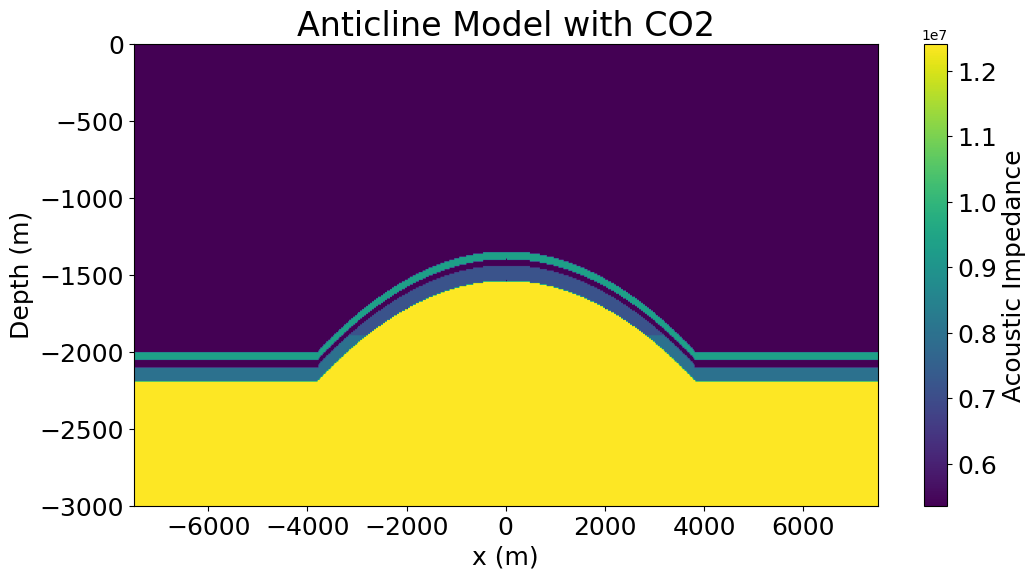

In [14]:
#here we are plotting the grid at some y value
plt.figure(figsize = (12,6))
plt.imshow(AI2b[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto')
cbar = plt.colorbar()
cbar.set_label('Acoustic Impedance',fontsize=18)
plt.title('Anticline Model with CO2', fontsize=24)
plt.xlabel('x (m)',fontsize=18)
plt.ylabel('Depth (m)',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
#plt.axhline(y=-2200)
#plt.axvline(x=-3840)
#plt.plot(seis2b[375,375,:]*3000,zs, color = 'w')
plt.savefig('anticlinemodel_co2.pdf', bbox_inches='tight')

## Model 3a

Now we will model a reservoir truncating against a diapir

In [3]:
#here we are defining our seismic velocities and density within the grid
vp3a = 2840.0 * np.ones_like(xx)
#vs3a = 1700.0 * np.ones_like(xx)
rho3a = 2440.0 * np.ones_like(xx)

#here we define the Petrel properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<=((4276*math.e**(-(xx**2+yy**2)/1000000))-2400)) & (zz>((4276*math.e**(-(xx**2+yy**2)/1000000))-2450)) & (xx**2+yy**2 > 1750**2))
vp3a[ix_to_change,iy_to_change,iz_to_change]=4715.
rho3a[ix_to_change,iy_to_change,iz_to_change]=2220.

#Here we define the eider properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<=((4276*math.e**(-(xx**2+yy**2)/1000000))-2500)) & (zz>=((4276*math.e**(-(xx**2+yy**2)/1000000))-2600)) & (xx**2+yy**2 > 1750**2))
vp3a[ix_to_change,iy_to_change,iz_to_change]=4024.
rho3a[ix_to_change,iy_to_change,iz_to_change]=2290.

#here we define the lower properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<((4276*math.e**(-(xx**2+yy**2)/1000000))-2600)) & (xx**2+yy**2 > 1750**2))
vp3a[ix_to_change,iy_to_change,iz_to_change]=3695.
rho3a[ix_to_change,iy_to_change,iz_to_change]=2350.

#here we define the diapir
ix_to_change,iy_to_change,iz_to_change=np.where((xx**2+yy**2 < 1750**2) & (zz<-1450))
vp3a[ix_to_change,iy_to_change,iz_to_change]=4482.
rho3a[ix_to_change,iy_to_change,iz_to_change]=2450.

ix_to_change,iy_to_change,iz_to_change=np.where((zz>-1460) & (xx**2+yy**2+(3*zz+4500)**2 < 1750**2))
vp3a[ix_to_change,iy_to_change,iz_to_change]=4482.
rho3a[ix_to_change,iy_to_change,iz_to_change]=2450.

In [4]:
AI3a=np.multiply(vp3a,rho3a)

#calculate reflectivity coefficient
RC3a = np.zeros_like(AI3a)
for x in range(751):
    for y in range(751):
        for z in range(300):
            RC3a[x,y,z] = (AI3a[x,y,z+1] - AI3a[x,y,z])/(AI3a[x,y,z+1] + AI3a[x,y,z])

In [ ]:
#here we are plotting the grid at some y value
plt.figure(figsize = (14,7))
plt.imshow(AI3a[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect=2)
#plt.axhline(z[209])
cbar = plt.colorbar()
cbar.set_label('Acoustic Impedance',fontsize=12)
plt.title('Diapir Truncation Model at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
cbar.ax.tick_params(labelsize=12)
#plt.plot(seis3a[375,375,:]*3000,z, color = 'w')
#plt.savefig('truncmodel.pdf')

# Model 3B
This is a diapir truncation model including CO2

In [31]:
#here we are defining our seismic velocities and density within the grid
vp3b = 2840.0 * np.ones_like(xx)
#vs3b = 1700.0 * np.ones_like(xx)
rho3b = 2440.0 * np.ones_like(xx)

#here we define the Petrel properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<=((4276*math.e**(-(xx**2+yy**2)/1000000))-2400)) & (zz>((4276*math.e**(-(xx**2+yy**2)/1000000))-2450)) & (xx**2+yy**2 > 1750**2))
vp3b[ix_to_change,iy_to_change,iz_to_change]=4715.
rho3b[ix_to_change,iy_to_change,iz_to_change]=2220.

#Here we define the eider properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<=((4276*math.e**(-(xx**2+yy**2)/1000000))-2500)) & (zz>=((4276*math.e**(-(xx**2+yy**2)/1000000))-2600)) & (xx**2+yy**2 > 1750**2))
vp3b[ix_to_change,iy_to_change,iz_to_change]=4024.
rho3b[ix_to_change,iy_to_change,iz_to_change]=2290.

#Here we define the co2 properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<=((4276*math.e**(-(xx**2+yy**2)/1000000))-2500)) & (zz>((4276*math.e**(-(xx**2+yy**2)/1000000))-2600)) & (xx**2+yy**2 > 1750**2) & (xx**2 + yy**2 < 4000**2))
vp3b[ix_to_change,iy_to_change,iz_to_change]=3620.
rho3b[ix_to_change,iy_to_change,iz_to_change]=2290.

#here we define the lower properties
ix_to_change,iy_to_change,iz_to_change=np.where((zz<((4276*math.e**(-(xx**2+yy**2)/1000000))-2600)) & (xx**2+yy**2 > 1750**2))
vp3b[ix_to_change,iy_to_change,iz_to_change]=3695.
rho3b[ix_to_change,iy_to_change,iz_to_change]=2350.

#here we define the diapir
ix_to_change,iy_to_change,iz_to_change=np.where((xx**2+yy**2 < 1750**2) & (zz<-1450))
vp3b[ix_to_change,iy_to_change,iz_to_change]=4482.
rho3b[ix_to_change,iy_to_change,iz_to_change]=2450.

ix_to_change,iy_to_change,iz_to_change=np.where((zz>-1460) & (xx**2+yy**2+(3*zz+4500)**2 < 1750**2))
vp3b[ix_to_change,iy_to_change,iz_to_change]=4482.
rho3b[ix_to_change,iy_to_change,iz_to_change]=2450.

In [32]:
AI3b=np.multiply(vp3b,rho3b)

#calculate reflectivity coefficient
RC3b = np.zeros_like(AI3b)
for x in range(751):
    for y in range(751):
        for z in range(300):
            RC3b[x,y,z] = (AI3b[x,y,z+1] - AI3b[x,y,z])/(AI3b[x,y,z+1] + AI3b[x,y,z])

In [ ]:
#here we are plotting the grid at some y value
plt.figure(figsize = (15,6))
plt.imshow(AI3b[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto')
#plt.axhline(x=-400)
cbar = plt.colorbar()
cbar.set_label('Acoustic Impedance',fontsize=18)
plt.title('Diapir Truncation Model with CO2 at y = 0 m', fontsize = 20)
plt.xlabel('x (m)',fontsize=18)
plt.ylabel('Depth (m)',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
plt.savefig('truncmodel_co2.pdf')

## Layer Cake Model

So far we have only modelled CO2 at trapping structures. We also want to model CO2 in areas of typical geometry. This involves a simple layer-cake geometry.

In [ ]:
#here we are defining our seismic velocities and density within the grid
vp4 = 4500.0 * np.ones_like(xx)
vs4 = 2800.0 * np.ones_like(xx)
rho4 = 2600.0 * np.ones_like(xx)

#here we define the eider/reservoir
ix_to_change,iy_to_change,iz_to_change=np.where((zz<-1000) & (zz>-1400))
vp4[ix_to_change,iy_to_change,iz_to_change]=2900.
vs4[ix_to_change,iy_to_change,iz_to_change]=1500.

#here we define the CO2
ix_to_change,iy_to_change,iz_to_change=np.where((zz<-1000) & (zz>-1200))
vp4[ix_to_change,iy_to_change,iz_to_change]=2400.
vs4[ix_to_change,iy_to_change,iz_to_change]=1300.

#here we define the eider bottom and lower properties
ix_to_change,iy_to_change,iz_to_change=np.where(zz<-1400)
vp4[ix_to_change,iy_to_change,iz_to_change]=4000.
vs4[ix_to_change,iy_to_change,iz_to_change]=2500.


In [ ]:
#here we are plotting the grid at some y value
plt.figure(figsize = (10,5))
plt.imshow(vp4[100,:,:].T, origin='lower', extent=[-2000,2000,-2000,0])
#plt.axhline(x=-400)
cbar = plt.colorbar()
cbar.set_label('P-wave velocity (m/s)',fontsize=12)
plt.title('Diapir Truncation Model at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
cbar.ax.tick_params(labelsize=12)
plt.savefig('flatmodel.pdf')

# Noise
To test to make sure that the CO2 would be visible in the seismic data, we need to make another model with random noise.\
We will do this by making a model of the same size as before, and filling it with random numbers of some range between what is in the reflectivtiy models.\
We will then convolve this model with the noise wavelet extracted from the seismic data, and add the resulting seismic data to the clean data from the reflectivity models.

In [ ]:
np.max(RC3b)

In [31]:
#noise for models 1 and 2
#n_rc_6db_a = np.random.normal(0,0.0675,(751,751,301))
#n_rc_6db_b = np.random.normal(0,0.0675,(751,751,301))
#n_rc_10db_a = np.random.normal(0,0.027,(751,751,301))
#n_rc_10db_b = np.random.normal(0,0.027,(751,751,301))
n_rc_15db_a = np.random.normal(0,0.0087,(751,751,301))
n_rc_15db_b = np.random.normal(0,0.0087,(751,751,301))
#n_rc_20db_a = np.random.normal(0,0.0027,(751,751,301))
#n_rc_20db_b = np.random.normal(0,0.0027,(751,751,301))

In [ ]:
# noise for model 3
#n_rc_6db_a = np.random.normal(0,0.0508,(751,751,301))
#n_rc_6db_b = np.random.normal(0,0.0508,(751,751,301))
#n_rc_10db_a = np.random.normal(0,0.0203,(751,751,301))
#n_rc_10db_b = np.random.normal(0,0.0203,(751,751,301))
n_rc_15db_a = np.random.normal(0,0.00633,(751,751,301))
n_rc_15db_b = np.random.normal(0,0.00633,(751,751,301))
n_rc_20db_a = np.random.normal(0,0.00203,(751,751,301))
n_rc_20db_b = np.random.normal(0,0.00203,(751,751,301))

In [ ]:
np.max(RC3b)

# Convolution

Now that we have the models set up, we can convolve them with a wavelet to generate pseudo-seismic.\
We will use wavelets extracted from the seismic data in the region we are modelling.

In [16]:
anti_wavelet = np.loadtxt("Anticline_model_ext_stat.txt", dtype=float)
pinch_wavelet = np.loadtxt("Pinchout_model_ext_stat.txt", dtype=float)
trunc_wavelet = np.loadtxt("Diapir_model_ext_stat.txt", dtype=float)
noise_wavelet = np.loadtxt("noise_wavelet_int.txt", dtype=float)

In [ ]:
seis1a = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis1a[x,y] = np.convolve(pinch_wavelet, RC1a[x,y])[33:-31]

seis1b = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis1b[x,y] = np.convolve(pinch_wavelet, RC1b[x,y])[33:-31]

In [17]:
seis2a = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis2a[x,y] = np.convolve(anti_wavelet, RC2a[x,y])[33:-31]

seis2b = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis2b[x,y] = np.convolve(anti_wavelet, RC2b[x,y])[33:-31]

In [33]:
seis3a = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis3a[x,y] = np.convolve(trunc_wavelet, RC3a[x,y])[33:-31]

seis3b = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis3b[x,y] = np.convolve(trunc_wavelet, RC3b[x,y])[33:-31]

In [18]:
seis_n_6db_a = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis_n_6db_a[x,y] = np.convolve(noise_wavelet, n_rc_6db_a[x,y])[33:-31]

seis_n_6db_b = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis_n_6db_b[x,y] = np.convolve(noise_wavelet, n_rc_6db_b[x,y])[33:-31]

In [19]:
seis_n_10db_a = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis_n_10db_a[x,y] = np.convolve(noise_wavelet, n_rc_10db_a[x,y])[33:-31]

seis_n_10db_b = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis_n_10db_b[x,y] = np.convolve(noise_wavelet, n_rc_10db_b[x,y])[33:-31]

In [32]:
seis_n_15db_a = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis_n_15db_a[x,y] = np.convolve(noise_wavelet, n_rc_15db_a[x,y])[33:-31]

seis_n_15db_b = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis_n_15db_b[x,y] = np.convolve(noise_wavelet, n_rc_15db_b[x,y])[33:-31]

In [ ]:
seis_n_20db_a = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis_n_20db_a[x,y] = np.convolve(noise_wavelet, n_rc_20db_a[x,y])[33:-31]

seis_n_20db_b = np.zeros(shape = (751,751,301))
for x in range(751):
    for y in range(751):
        seis_n_20db_b[x,y] = np.convolve(noise_wavelet, n_rc_20db_b[x,y])[33:-31]

In [ ]:
#seis_1a_n_6db = seis1a + seis_n_6db_a
#seis_1b_n_6db = seis1b + seis_n_6db_b

#seis_1a_n_10db = seis1a + seis_n_10db_a
#seis_1b_n_10db = seis1b + seis_n_10db_b

seis_1a_n_15db = seis1a + seis_n_15db_a
seis_1b_n_15db = seis1b + seis_n_15db_b

seis_1a_n_20db = seis1a + seis_n_20db_a
seis_1b_n_20db = seis1b + seis_n_20db_b

In [33]:
#seis_2a_n_6db = seis2a + seis_n_6db_a
#seis_2b_n_6db = seis2b + seis_n_6db_b

#seis_2a_n_10db = seis2a + seis_n_10db_a
#seis_2b_n_10db = seis2b + seis_n_10db_b

seis_2a_n_15db = seis2a + seis_n_15db_a
seis_2b_n_15db = seis2b + seis_n_15db_b

#seis_2a_n_20db = seis2a + seis_n_20db_a
#seis_2b_n_20db = seis2b + seis_n_20db_b

In [ ]:
#seis_3a_n_6db = seis3a + seis_n_6db_a
#seis_3b_n_6db = seis3b + seis_n_6db_b

#seis_3a_n_10db = seis3a + seis_n_10db_a
#seis_3b_n_10db = seis3b + seis_n_10db_b

seis_3a_n_15db = seis3a + seis_n_15db_a
seis_3b_n_15db = seis3b + seis_n_15db_b

seis_3a_n_20db = seis3a + seis_n_20db_a
seis_3b_n_20db = seis3b + seis_n_20db_b

In [ ]:
zs = np.linspace(0.0, -3000.0, 333)

In [ ]:
diff_1 = seis1a - seis1b
#diff_1_n_6db = seis_1a_n_6db - seis_1b_n_6db
#diff_1_n_10db = seis_1a_n_10db - seis_1b_n_10db
#diff_1_n_15db = seis_1a_n_15db - seis_1b_n_15db
#diff_1_n_20db = seis_1a_n_20db - seis_1b_n_20db

In [34]:
#calculating the difference between the a and b versions of the models
diff_2 = seis2a - seis2b
#diff_2_n_6db = seis_2a_n_6db - seis_2b_n_6db
#diff_2_n_10db = seis_2a_n_10db - seis_2b_n_10db
diff_2_n_15db = seis_2a_n_15db - seis_2b_n_15db
#diff_2_n_20db = seis_2a_n_20db - seis_2b_n_20db

In [34]:
diff_3 = seis3a - seis3b
#diff_3_n_6db = seis_3a_n_6db - seis_3b_n_6db
#diff_3_n_10db = seis_3a_n_10db - seis_3b_n_10db
#diff_3_n_15db = seis_3a_n_15db - seis_3b_n_15db
#diff_3_n_20db = seis_3a_n_20db - seis_3b_n_20db

In [ ]:
np.max(diff_3)

In [ ]:
#creating new colormaps to lock the midpoint at zero for plotting
seis1a_min = np.min(seis1a)
seis1a_max = np.max(seis1a)
seis1b_min = np.min(seis1b)
seis1b_max = np.max(seis1b)
diff_1_min = np.min(diff_1)
diff_1_max = np.max(diff_1)
custom_norm_1a=colors.TwoSlopeNorm(vmin=seis1a_min, vcenter=0., vmax=seis1a_max)
custom_norm_1b=colors.TwoSlopeNorm(vmin=seis1b_min, vcenter=0., vmax=seis1b_max)
custom_norm_diff_1=colors.TwoSlopeNorm(vmin=diff_1_min, vcenter=0., vmax=diff_1_max)

In [22]:
seis2a_min = np.min(seis2a)
seis2a_max = np.max(seis2a)
seis2b_min = np.min(seis2b)
seis2b_max = np.max(seis2b)
diff_2_min = np.min(diff_2)
diff_2_max = np.max(diff_2)
custom_norm_2a=colors.TwoSlopeNorm(vmin=seis2a_min, vcenter=0., vmax=seis2a_max)
custom_norm_2b=colors.TwoSlopeNorm(vmin=seis2b_min, vcenter=0., vmax=seis2b_max)
custom_norm_diff_2=colors.TwoSlopeNorm(vmin=diff_2_min, vcenter=0., vmax=diff_2_max)


In [10]:
seis3a_min = np.min(seis3a)
seis3a_max = np.max(seis3a)
seis3b_min = np.min(seis3b)
seis3b_max = np.max(seis3b)
diff_3_min = np.min(diff_3)
diff_3_max = np.max(diff_3)
custom_norm_3a=colors.TwoSlopeNorm(vmin=seis3a_min, vcenter=0., vmax=seis3a_max)
custom_norm_3b=colors.TwoSlopeNorm(vmin=seis3b_min, vcenter=0., vmax=seis3b_max)
custom_norm_diff_3=colors.TwoSlopeNorm(vmin=diff_3_min, vcenter=0., vmax=diff_3_max)

In [ ]:
print(seis3a_max)
print(seis3b_max)
print(diff_3_max)

# Plotting Clean Data

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(seis1a[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm=custom_norm_1b)

cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=20)
plt.title('Pinchout data at y = 0 m', fontsize = 24)
plt.xlabel('x (m)',fontsize=20)
plt.ylabel('Depth (m)',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig('pinchout_pseudo_seismic_10.pdf', bbox_inches='tight')

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(seis1b[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm=custom_norm_1b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=20)
plt.title('Pinchout with CO2 data', fontsize=24)
plt.xlabel('x (m)',fontsize=20)
plt.ylabel('Depth (m)',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig('pinchout_co2_pseudo_seismic_10.pdf', bbox_inches='tight')

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(diff_1[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm = custom_norm_1b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=20)
plt.title('Pinchout data difference at y = 0 m', fontsize = 24)
plt.xlabel('x (m)',fontsize=20)
plt.ylabel('Depth (m)',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig('pinchout_diff_10.pdf', bbox_inches='tight')

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(seis2a[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm=custom_norm_2b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=20)
plt.title('Anticline data',fontsize=24)
plt.xlabel('x (m)',fontsize=20)
plt.ylabel('Depth (m)',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)

plt.savefig('anticline_pseudo_seismic_10.pdf', bbox_inches='tight')

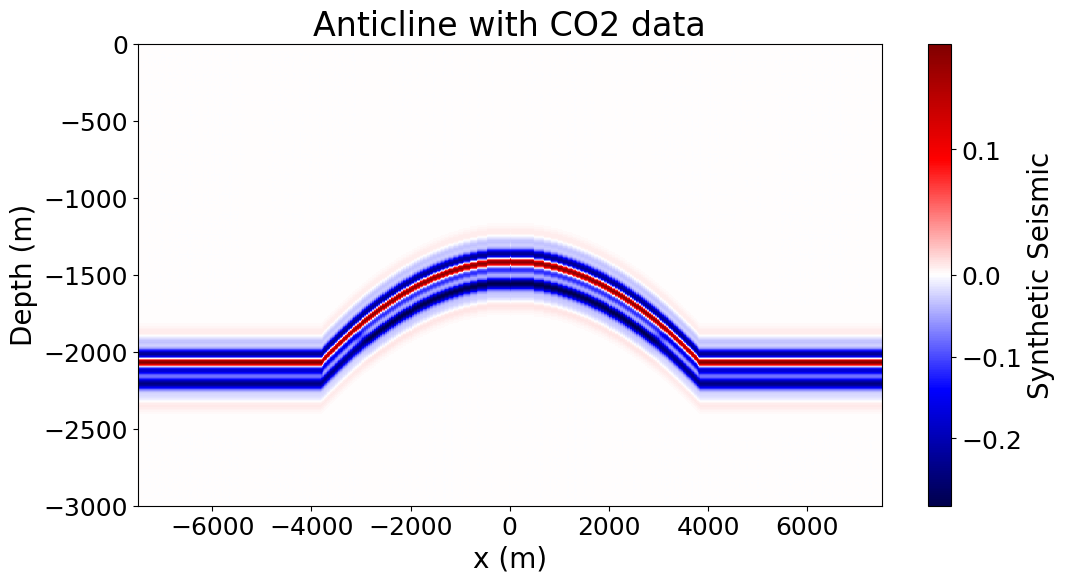

In [24]:
plt.figure(figsize = (12,6))
plt.imshow(seis2b[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm=custom_norm_2b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=20)
plt.title('Anticline with CO2 data',fontsize=24)
plt.xlabel('x (m)',fontsize=20)
plt.ylabel('Depth (m)',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig('anticline_co2_pseudo_seismic_10.pdf', bbox_inches='tight')

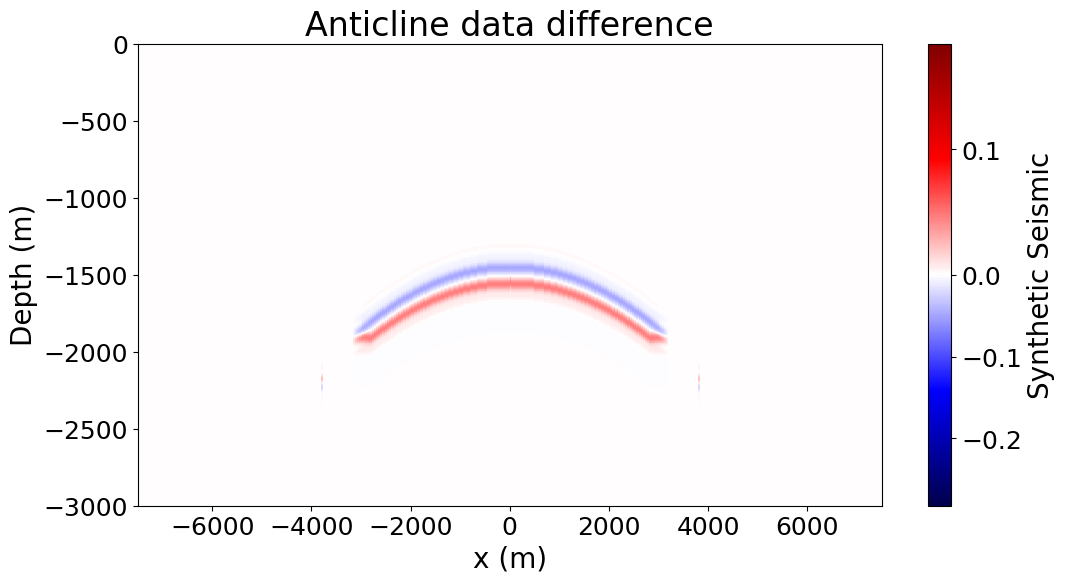

In [26]:
plt.figure(figsize = (12,6))
plt.imshow(diff_2[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm = custom_norm_2b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=20)
plt.title('Anticline data difference',fontsize=24)
plt.xlabel('x (m)',fontsize=20)
plt.ylabel('Depth (m)',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig('anticline_diff_10.pdf', bbox_inches='tight')

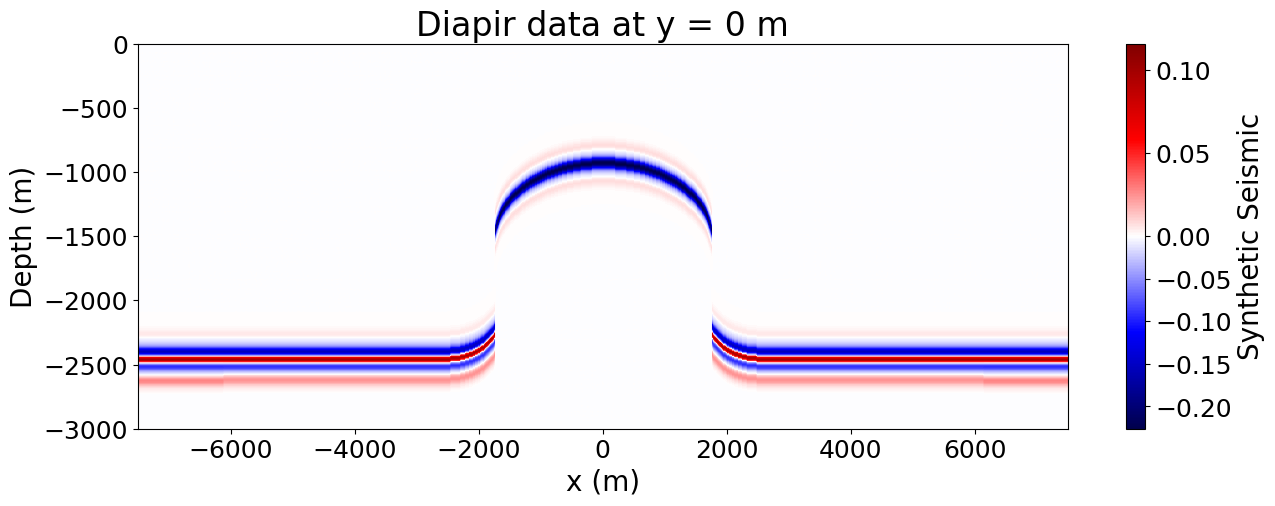

In [36]:
plt.figure(figsize = (15,5))
plt.imshow(seis3a[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm=custom_norm_3b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=20)
plt.title('Diapir data at y = 0 m',fontsize=24)
plt.xlabel('x (m)',fontsize=20)
plt.ylabel('Depth (m)',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig('diapir_pseudo_seismic_10.pdf', bbox_inches='tight')

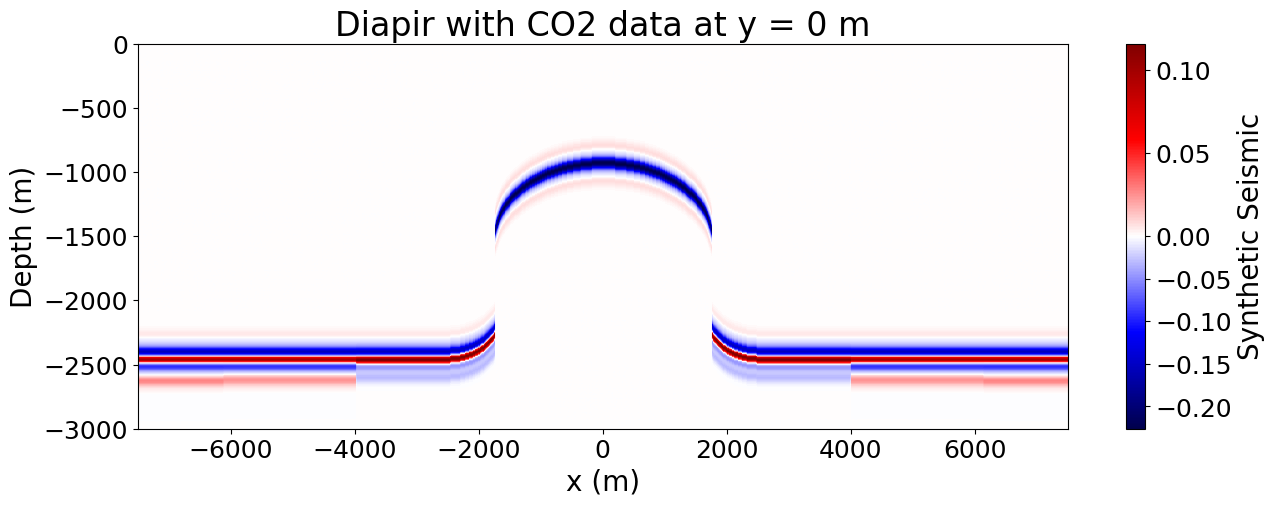

In [37]:
plt.figure(figsize = (15,5))
plt.imshow(seis3b[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm=custom_norm_3b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=20)
plt.title('Diapir with CO2 data at y = 0 m',fontsize=24)
plt.xlabel('x (m)',fontsize=20)
plt.ylabel('Depth (m)',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig('diapir_co2_pseudo_seismic_10.pdf', bbox_inches='tight')

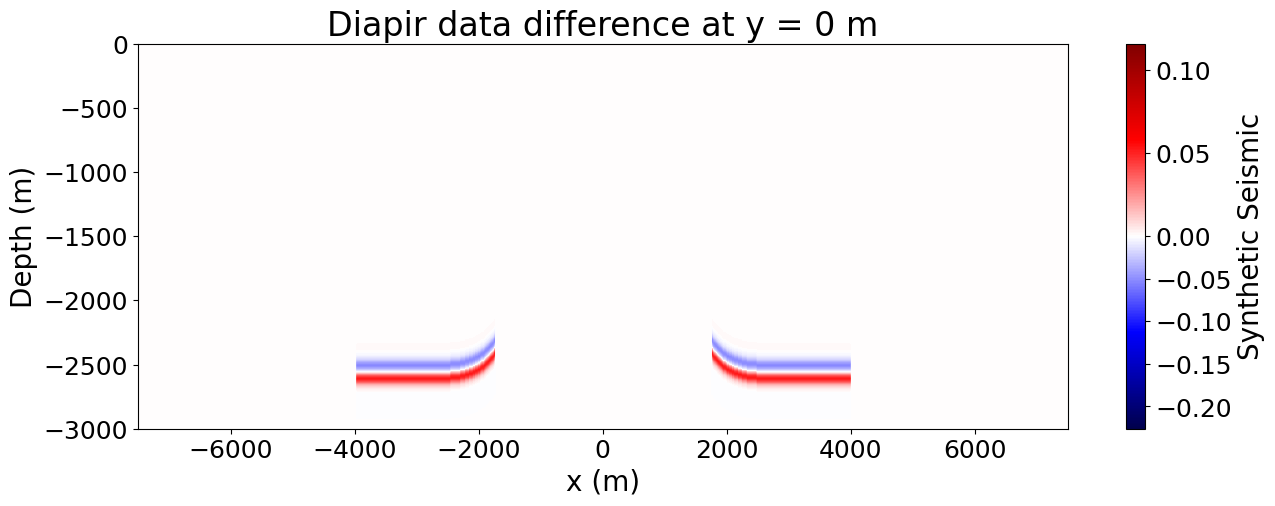

In [35]:
plt.figure(figsize = (15,5))
plt.imshow(diff_3[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm = custom_norm_3b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=20)
plt.title('Diapir data difference at y = 0 m',fontsize=24)
plt.xlabel('x (m)',fontsize=20)
plt.ylabel('Depth (m)',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig('diapir_diff_10_og.pdf', bbox_inches='tight')

# Plotting Noisy Data

## Noisy Pinchout

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(seis_1a_n_6db[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic',norm=custom_norm_1b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=12)
plt.title('SNR=6dB Pinchout at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
cbar.ax.tick_params(labelsize=12)
plt.savefig("pinchout_6db_noise_5.pdf", bbox_inches='tight')

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(seis_1b_n_20db[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm=custom_norm_1b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=12)
plt.title('SNR=20dB Pinchout with CO2 at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
cbar.ax.tick_params(labelsize=12)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig("pinchout_co2_20db_noise_15.pdf", bbox_inches='tight')

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(diff_1_n_20db[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm = custom_norm_1b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=12)
plt.title('SNR=20dB Pinchout Difference at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
cbar.ax.tick_params(labelsize=12)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig("pinchout_diff_20db_noise_15.pdf", bbox_inches='tight')

## Noisy Anticline

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(seis_2a_n_6db[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic',norm=custom_norm_2b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=12)
plt.title('SNR=6dB Anticline at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
cbar.ax.tick_params(labelsize=12)
plt.savefig("anticline_6db_noise.pdf", bbox_inches='tight')

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(seis_2b_n_20db[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm=custom_norm_2b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=12)
plt.title('SNR=20dB Anticline with CO2 at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
cbar.ax.tick_params(labelsize=12)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig("anticline_co2_20db_noise_15.pdf", bbox_inches='tight')

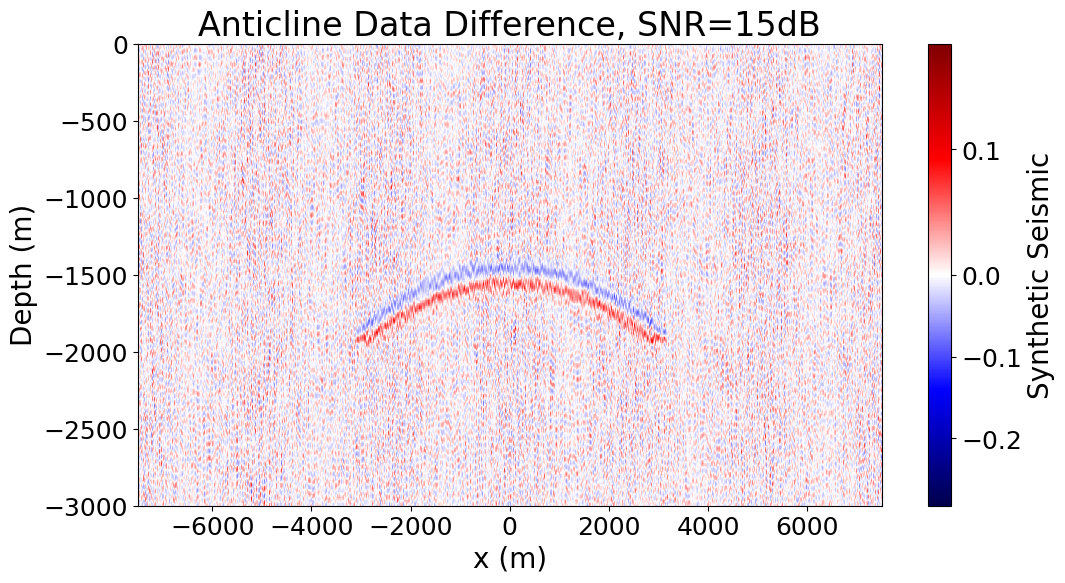

In [35]:
plt.figure(figsize = (12,6))
plt.imshow(diff_2_n_15db[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm = custom_norm_2b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=20)
plt.title('Anticline Data Difference, SNR=15dB', fontsize=24)
plt.xlabel('x (m)',fontsize=20)
plt.ylabel('Depth (m)',fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
cbar.ax.tick_params(labelsize=18)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig("anticline_diff_15db_noise_10.pdf", bbox_inches='tight')

## Noisy Diapir

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(seis_3a_n_6db[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic',norm=custom_norm_3b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=12)
plt.title('SNR=6dB Diapir Truncation at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
cbar.ax.tick_params(labelsize=12)
plt.savefig("diapir_6db_noise.pdf", bbox_inches='tight')

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(seis_3b_n_20db[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm=custom_norm_3b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=12)
plt.title('SNR=20dB Diapir Truncation with CO2 at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
cbar.ax.tick_params(labelsize=12)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig("diapir_co2_20db_noise_15.pdf", bbox_inches='tight')

In [ ]:
plt.figure(figsize = (15,5))
plt.imshow(diff_3_n_20db[375,:,:].T, origin='lower', extent=[-7500,7500,-3000,0], aspect='auto', cmap='seismic', norm = custom_norm_3b)
cbar = plt.colorbar()
cbar.set_label('Synthetic Seismic',fontsize=12)
plt.title('SNR=20dB Diapir Difference at y = 0 m')
plt.xlabel('x (m)',fontsize=12)
plt.ylabel('Depth (m)',fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
cbar.ax.tick_params(labelsize=12)
#plt.axhline(y=-1350)
#plt.axhline(y=-1750)
plt.savefig("diapir_diff_20db_noise_15.pdf", bbox_inches='tight')